# Crustal stress patterns in Central Europe – World Stress Map 2025

Step-by-step version of `run_analysis.py`:
load → inspect → clean → GeoDataFrame → study area → quality filter → statistics → maps → CASMO-like filter → export.

**Data:** Heidbach et al. (2025), *World Stress Map Database Release 2025*, GFZ Data Services, https://doi.org/10.5880/WSM.2025.001 (CC BY 4.0).
Field definitions: WSM Technical Report 25-01, https://doi.org/10.48440/wsm.2025.001.

## 1. Short background

- **SHmax** = maximum horizontal stress. The WSM stores its orientation (azimuth from north, 0–180°).
- It is an **axis**: 0° and 180° are the same orientation, so normal averaging does not work.
- **Quality A–E**: A ±15°, B ±20°, C ±25°, D ±40°, E worse or no orientation. New in 2025: Xmi / Xne / Xru. A–C are used for analysis.
- **Regime**: NF normal, SS strike-slip, TF thrust (NS, TS transitional, U unknown).
- **Indicators**: earthquake focal mechanisms (FMS/FMF), borehole breakouts (BO), drilling-induced fractures (DIF), hydraulic fracturing (HF), overcoring (OC), and others.

More details in `docs/wsm_fields.md`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.width", 160, "display.max_columns", 20)

from src.data_processing import *
from src.filtering import *
from src.orientation_stats import *
from src import plotting as P
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "dpi": 80}  # light inline figures (saved files use 300 dpi)
print("Project root:", ROOT)

Project root: /home/claude/github_repo/world-stress-map-central-europe


## 2. Load the raw WSM 2025 file
The CSV is downloaded from GFZ Data Services if it is not yet in `data/raw/`. Its SHA-256 checksum is compared with the documented value so that everybody uses exactly the same file.

In [2]:
raw_path = RAW_DIR / WSM_FILENAME
raw = load_wsm_data(raw_path)
print("Shape:", raw.shape)
print("SHA-256 matches documented value:", sha256_of(raw_path) == WSM_SHA256)
raw.head(3)

Shape: (100842, 40)
SHA-256 matches documented value: True


,ID,ISC_ID,SITE,LAT,LON,AZI,TYPE,DEPTH,QUALITY,REGIME,...,CRUST,REF1,REF2,REF3,REF4,REF5,REF6,COMMENT,PLATE,DIST
0,wsm00015,NaN,TU42,36.88,30.67,0,OC,0.31,C,U,...,True,CAKIXX1971,NaN,NaN,NaN,NaN,NaN,FRSDB,AT,170.0
1,wsm00016,NaN,TU41,40.18,29.10,0,OC,0.17,B,NF,...,True,KOSEXX1983,NaN,NaN,NaN,NaN,NaN,FRSDB,AT,57.0
2,wsm00017,NaN,TU40,41.80,33.69,0,OC,0.16,C,NF,...,True,PASAET1984,NaN,NaN,NaN,NaN,NaN,FRSDB,EU,87.0


## 3. Inspect the schema
We do **not** assume column names – we look at the real file first.

In [3]:
schema = describe_schema(raw)
schema

,column,dtype,n_missing,pct_missing,n_unique,example
0,ID,str,0,0.0,100842,wsm00015
1,ISC_ID,float64,22527,22.3,78315,8646422.0
2,SITE,str,94295,93.5,6118,TU42
3,LAT,float64,170,0.2,24139,36.88
4,LON,float64,170,0.2,34382,30.67
5,AZI,int64,0,0.0,182,0
6,TYPE,str,0,0.0,16,OC
7,DEPTH,float64,0,0.0,2807,0.31
8,QUALITY,str,0,0.0,8,C
9,REGIME,str,0,0.0,6,U


### Key fields identified in the real file (definitions from WSM TR 25-01)

| Column | Meaning | Notes from inspection |
|---|---|---|
| `ID` | unique WSM record ID (e.g. `wsm00015`) | no duplicates |
| `LAT`, `LON` | latitude / longitude (WGS84, decimal degrees) | 170 records without coordinates (all Xmi) |
| `AZI` | SHmax azimuth, ° clockwise from north (0–180) | **999 = no orientation provided** |
| `TYPE` | stress-indicator type (FMS, BO, DIF, HF, OC, …) | 16 codes |
| `QUALITY` | WSM quality A–E, Xmi, Xne, Xru | |
| `REGIME` | stress regime NF, NS, SS, TS, TF, U | |
| `DEPTH` | depth of measurement in km | a few slightly negative values (above sea level) |
| `COUNTRY` | country name (or `Sea`) | used only for comparison |
| `REF1`…`REF6` | reference codes of the original publications | |
| `SD`, `NUMBER`, `TOT_LEN` | standard deviation, number of observations, total length (e.g. breakouts) | used for quality ranking |
| `S1AZ`…`S3PL` | azimuth/plunge of principal stresses (focal mechanisms) | |
| `PLATE`, `DIST` | plate (PB2002 model) and distance to plate boundary (km) | |
| `CRUST` | focal mechanism located within the crust | all `True` in this release |

In [4]:
for col in ["QUALITY", "TYPE", "REGIME"]:
    print(col, raw[col].value_counts().to_dict(), "\n")
print("AZI == 999:", (raw["AZI"] == 999).sum(), "| AZI range without 999:",
      raw.loc[raw["AZI"] != 999, "AZI"].agg(["min", "max"]).tolist())
print("Missing LAT/LON:", raw["LAT"].isna().sum())

QUALITY {'C': 73710, 'E': 13278, 'D': 8929, 'B': 1898, 'A': 1757, 'Xmi': 478, 'Xru': 464, 'Xne': 328} 

TYPE {'FMS': 85956, 'BO': 7465, 'DIF': 1789, 'FMF': 1370, 'GFI': 1220, 'HF': 1060, 'OC': 925, 'FMA': 429, 'GVA': 265, 'HFS': 119, 'GFM': 74, 'HFH': 53, 'SWB': 39, 'BS': 35, 'SWS': 23, 'SWL': 20} 

REGIME {'TF': 26270, 'NF': 25069, 'SS': 24162, 'U': 20944, 'NS': 2462, 'TS': 1935} 

AZI == 999: 11095 | AZI range without 999: [0, 180]
Missing LAT/LON: 170


## 4. Clean and validate
`clean_wsm_data()` removes records without coordinates, converts `AZI = 999` to *missing*, maps 180° to 0° (same axis) and adds helper columns. Nothing else is deleted – records without an azimuth stay in the quality statistics.

In [5]:
clean, log = clean_wsm_data(raw)
log

{'n_raw': 100842,
 'n_missing_coordinates': 170,
 'n_out_of_range_coordinates': 0,
 'missing_coordinates_quality': {'Xmi': 170},
 'n_azi_999_no_orientation': 11048,
 'azi_999_quality': {'E': 10996, 'Xmi': 36, 'Xru': 8, 'Xne': 7, 'B': 1},
 'n_azi_out_of_range': 0,
 'n_azi_equal_180_converted_to_0': 243,
 'n_duplicate_ids': 0,
 'n_identical_location_azi_type_depth_quality': 1629,
 'n_clean': 100672,
 'n_clean_with_azimuth': 89624}

In [6]:
# simple validation checks
assert clean["LAT"].between(-90, 90).all() and clean["LON"].between(-180, 180).all()
assert ((clean["AZI"] >= 0) & (clean["AZI"] < 180) | clean["AZI"].isna()).all()
assert clean["ID"].is_unique
print("Coordinate, azimuth and ID checks passed.")

Coordinate, azimuth and ID checks passed.


## 5. GeoDataFrame and coordinate reference system
The WSM coordinates are geographic WGS84 → **EPSG:4326**. For maps we project to **ETRS89-LAEA Europe (EPSG:3035)**, an equal-area projection designed for Europe.

In [7]:
gdf = to_geodataframe(clean)
print(gdf.crs)
print("Map CRS:", CRS_MAP, "-", gpd.GeoSeries([], crs=CRS_MAP).crs.name)

EPSG:4326
Map CRS: EPSG:3035 - ETRS89-extended / LAEA Europe


## 6. Study area
Primary area: **Germany** (records inside the Natural Earth 1:10m polygon). Germany alone has ~300 A–C records, but they are concentrated in a few basins, so the map is extended to a **Central Europe window (45.5–55.5°N, 2.5–19.5°E)** covering Germany, the Netherlands, Belgium, Luxembourg, Switzerland, Austria, Czechia, western Poland, Denmark (south), eastern France, northern Italy and parts of Slovenia, Hungary and Slovakia, plus offshore North Sea / Baltic records.

In [8]:
ce_all = filter_by_region(gdf, "Central Europe")
de_all = filter_by_region(gdf, "Germany")
print("Central Europe:", len(ce_all), "| Germany (polygon):", len(de_all),
      "| Germany (COUNTRY field):", (gdf["COUNTRY"] == "Germany").sum())
ce_all["COUNTRY"].value_counts().head(12)

Central Europe: 2216 | Germany (polygon): 791 | Germany (COUNTRY field): 786


COUNTRY
Germany           786
Switzerland       516
France            164
Italy             143
Austria           139
Sea               132
Hungary            84
Netherlands        80
Czech Republic     43
Slovakia           40
Poland             36
Slovenia           17
Name: count, dtype: int64[pyarrow]

## 7. Quality analysis

In [9]:
qtab = pd.concat([quality_counts(gdf).rename("global"),
                  quality_counts(ce_all).rename("Central Europe"),
                  quality_counts(de_all).rename("Germany")], axis=1)
qtab.loc["A–C total"] = qtab.loc[["A", "B", "C"]].sum()
qtab

,global,Central Europe,Germany
QUALITY,,,
A,1757,96,55
B,1898,173,70
C,73710,750,172
D,8929,673,301
E,13278,467,181
Xmi,308,1,1
Xne,328,20,8
Xru,464,36,3
A–C total,77365,1019,297


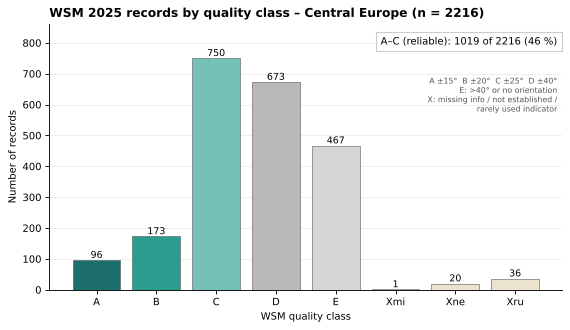

In [10]:
P.plot_quality_distribution(ce_all, title=f"WSM 2025 records by quality class – Central Europe (n = {len(ce_all)})");

In [11]:
ce_ac = filter_by_quality(ce_all, "C")
ce_ac = ce_ac[ce_ac["AZI"].notna()]
de_ac = filter_by_quality(de_all, "C"); de_ac = de_ac[de_ac["AZI"].notna()]
print("Central Europe A–C:", len(ce_ac), f"({100*len(ce_ac)/len(ce_all):.0f} %)  | Germany A–C:", len(de_ac))
print("Records without SHmax in Central Europe:", ce_all["AZI"].isna().sum(),
      ce_all.loc[ce_all["AZI"].isna(), "QUALITY"].astype(str).value_counts().to_dict())

Central Europe A–C: 1019 (46 %)  | Germany A–C: 297
Records without SHmax in Central Europe: 211 {'E': 204, 'Xne': 7}


## 8. Stress-indicator types

In [12]:
summary_by_indicator(ce_all)

,description,n_records,n_A_to_C,n_with_azimuth,median_depth_km,max_depth_km
TYPE,,,,,,
FMS,Single earthquake focal mechanism,921,546,834,8.00,33.00
BO,Borehole breakouts,875,343,765,1.59,6.14
OC,Overcoring / strain relief,129,10,129,0.01,2.50
HF,Hydraulic fracturing (sub-vertical wells),90,51,89,0.44,9.00
DIF,Drilling-induced tensile fractures,57,35,56,2.36,4.90
GFI,Inversion of geological fault-slip data,48,3,47,0.00,0.00
FMF,Formal inversion of several focal mechanisms,40,31,36,5.90,18.40
BS,Borehole slotter,35,0,35,0.01,0.80
SWL,Seismic anisotropy in laboratory,20,0,13,1.85,2.22


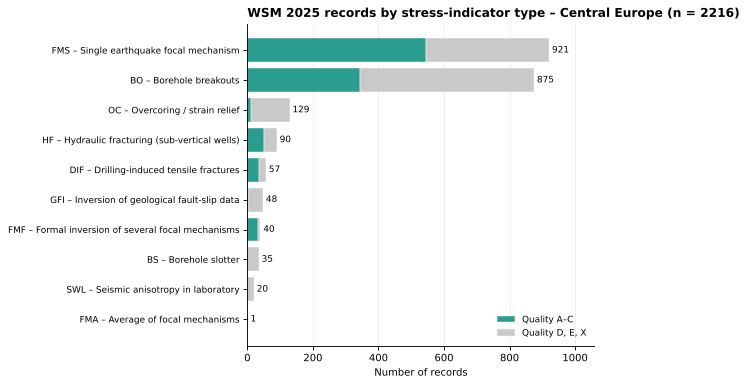

In [13]:
P.plot_indicator_distribution(ce_all, title=f"WSM 2025 records by stress-indicator type – Central Europe (n = {len(ce_all)})");

## 9. SHmax orientation analysis (axial statistics)

**Why not the normal average?** Take two almost identical N–S orientations, 170° and 10°. Their arithmetic mean is 90° (E–W) – completely wrong.

**Method (angle doubling):** (1) double each angle, (2) average the unit vectors (cos 2θ, sin 2θ), (3) halve the angle of the resulting vector. The length of the mean vector, **R**, is between 0 (no preferred orientation) and 1 (all parallel).

In [14]:
print("Arithmetic mean of 170° and 10°:", np.mean([170, 10]), "°  (wrong)")
print("Axial mean of 170° and 10°:     ", axial_mean([170, 10]))

Arithmetic mean of 170° and 10°: 90.0 °  (wrong)
Axial mean of 170° and 10°:      {'n': 2, 'mean_deg': 1.6923377980788397e-15, 'R': 0.9396926207859084, 'circ_std_deg': 10.104420288122428}


In [15]:
stats = pd.concat([
    orientation_summary(ce_ac).rename(index={"All": "Central Europe A–C"}),
    orientation_summary(ce_ac, weighted=True).rename(index={"All": "Central Europe A–C (quality-weighted)"}),
    orientation_summary(de_ac).rename(index={"All": "Germany A–C"}),
])
stats

,n,mean_deg,R,circ_std_deg,ci95_low,ci95_high,rayleigh_p
group,,,,,,,
Central Europe A–C,1019,154.940,0.494,34.045,152.534,157.308,0.0
Central Europe A–C (quality-weighted),1019,156.168,0.503,33.580,NaN,NaN,0.0
Germany A–C,297,168.297,0.561,30.807,164.522,172.068,0.0


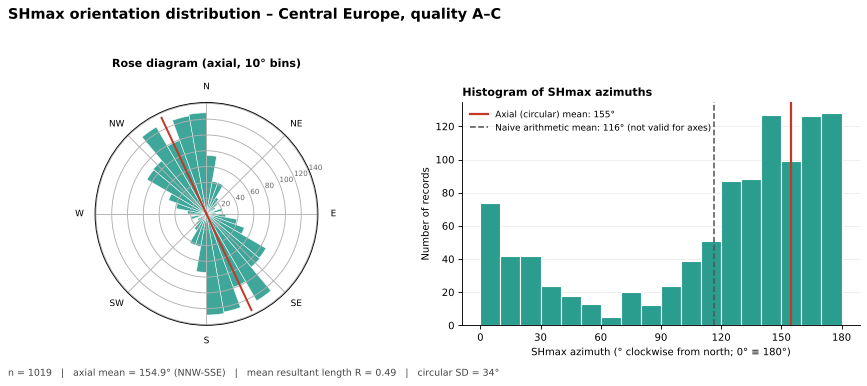

In [16]:
P.plot_orientation_distribution(ce_ac, title="SHmax orientation distribution – Central Europe, quality A–C");

In [17]:
orientation_summary(ce_ac, "TYPE")

,n,mean_deg,R,circ_std_deg,ci95_low,ci95_high,rayleigh_p
group,,,,,,,
BO,343,171.383,0.490,34.216,167.257,175.330,0.000
DIF,35,163.758,0.804,18.916,157.632,169.726,0.000
FMF,31,147.669,0.706,23.898,139.313,156.043,0.000
FMS,546,146.124,0.527,32.424,143.216,149.075,0.000
GFI,3,159.991,0.367,40.550,NaN,NaN,0.705
HF,51,148.420,0.635,27.291,139.676,156.722,0.000
OC,10,154.871,0.687,24.830,140.939,168.149,0.006


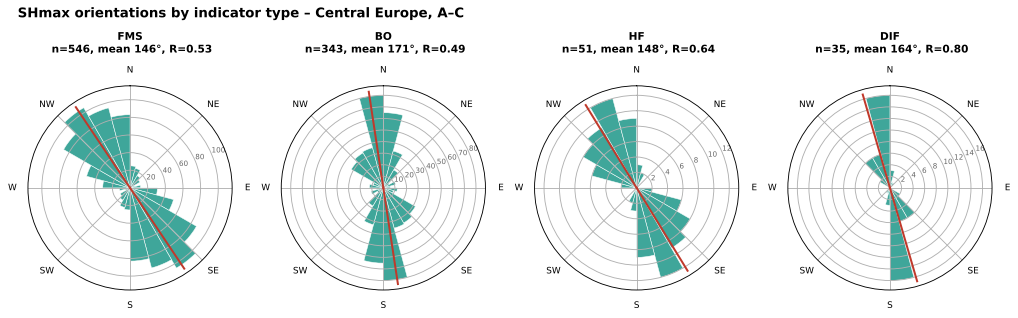

In [18]:
P.plot_rose_by_group(ce_ac, "TYPE", groups=["FMS", "BO", "HF", "DIF"],
                     title="SHmax orientations by indicator type – Central Europe, A–C");

A single regional mean hides spatial variation (R ≈ 0.5 means the orientations are only moderately consistent). A simple 1° grid of axial means shows *where* the orientation changes:

52 grid cells with ≥ 5 A–C records


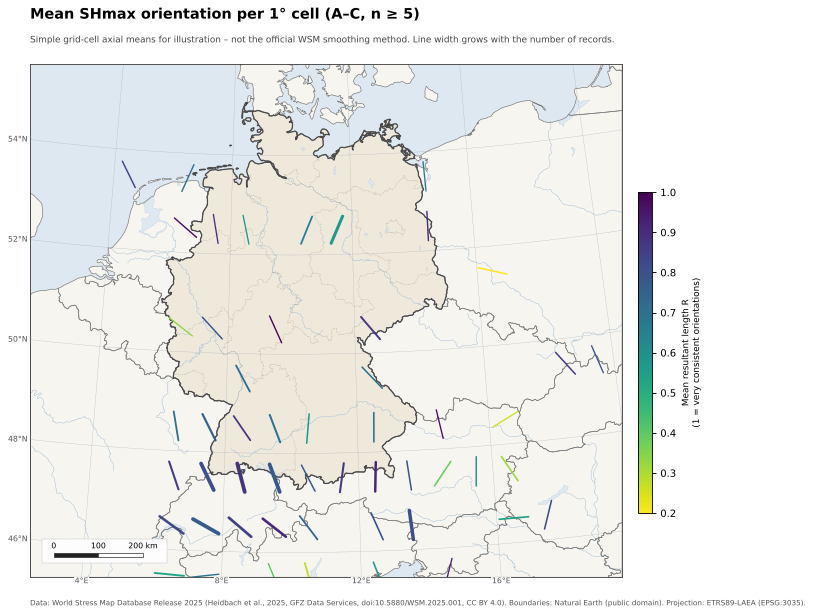

In [19]:
grid = gridded_axial_means(ce_ac, cell_deg=1.0, min_n=5)
print(len(grid), "grid cells with ≥ 5 A–C records")
P.plot_gridded_means(grid);

## 10. Stress maps
Each line is centred on a measurement and oriented along SHmax. End points are computed **geodesically** (pyproj `Geod.fwd`) and then projected, so the symbols point correctly relative to geographic north everywhere on the map. Colour = stress regime, length = quality.

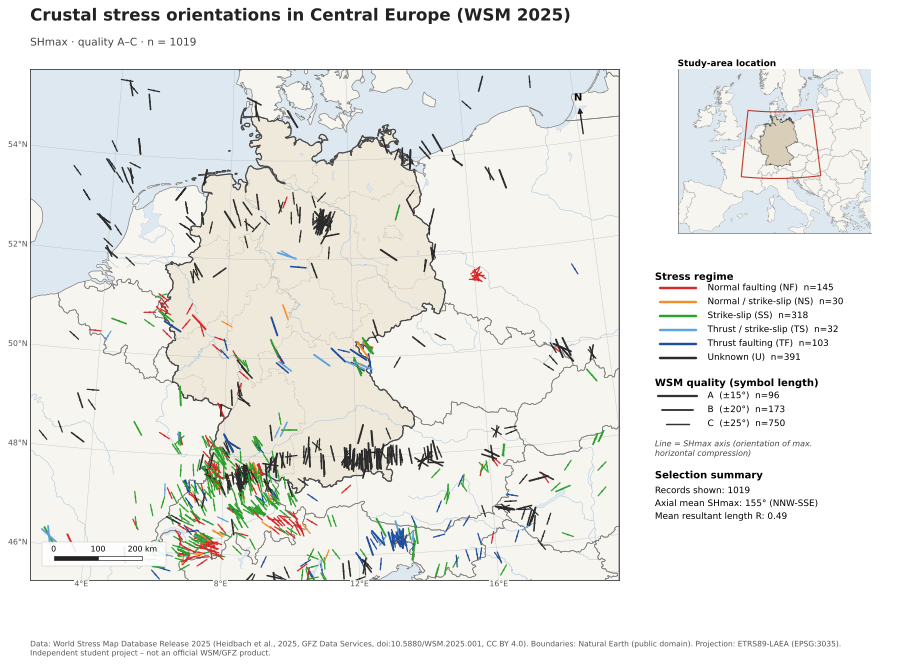

In [20]:
P.plot_stress_map(ce_ac, extent=REGION_PRESETS["Central Europe"]["map_extent"],
                  title="Crustal stress orientations in Central Europe (WSM 2025)",
                  subtitle=f"SHmax · quality A–C · n = {len(ce_ac)}");

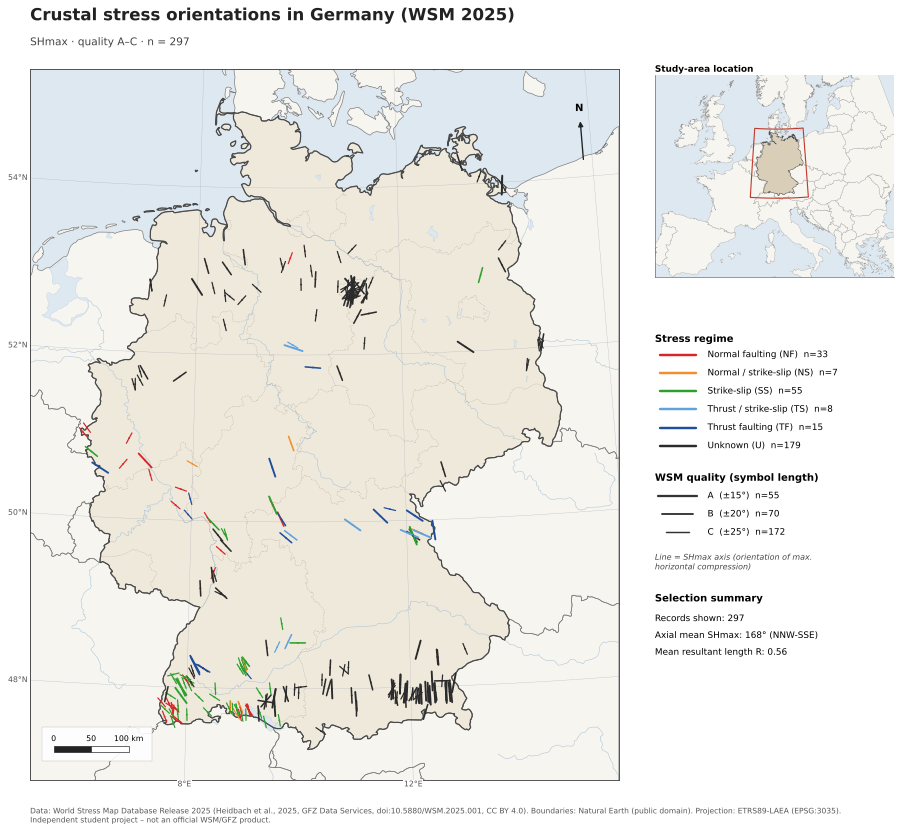

In [21]:
P.plot_stress_map(de_ac, extent=REGION_PRESETS["Germany"]["map_extent"],
                  title="Crustal stress orientations in Germany (WSM 2025)",
                  subtitle=f"SHmax · quality A–C · n = {len(de_ac)}");

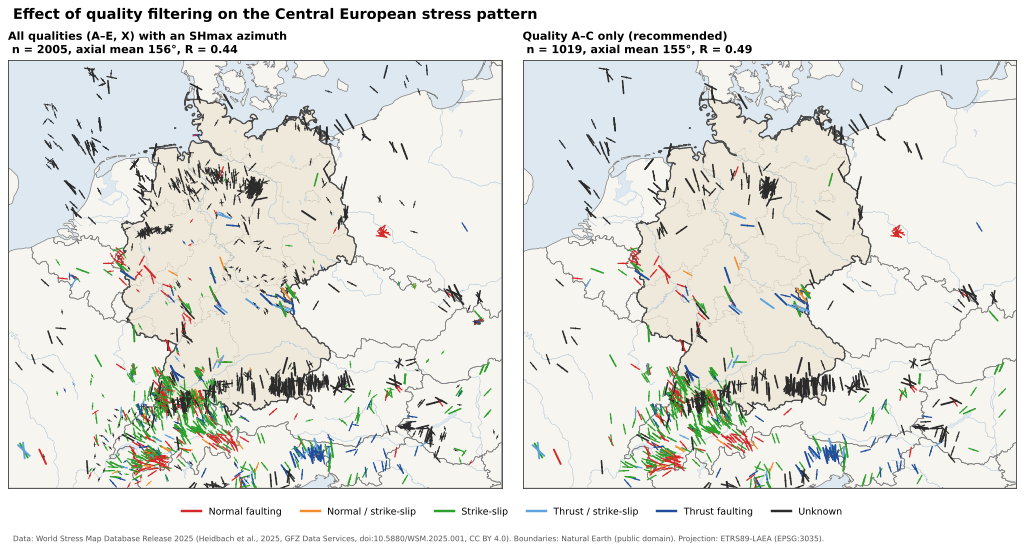

In [22]:
P.plot_quality_comparison(ce_all, ce_ac, extent=REGION_PRESETS["Central Europe"]["map_extent"]);

## 11. CASMO-inspired filtering workflow

CASMO (*Create A Stress Map Online*) lets users select a region, data quality, indicator types and regimes, and returns a stress map. `filter_stress_data()` reproduces this **concept** in Python:

`database → user filters → selected records → map`

CASMO-inspired filter -> region='Switzerland', quality='C', indicator='FM*', regime=None, depth=None
      filter_step  n_records
            input     100672
           region        518
          quality        297
        indicator        242
           regime        242
            depth        242
has SHmax azimuth        242


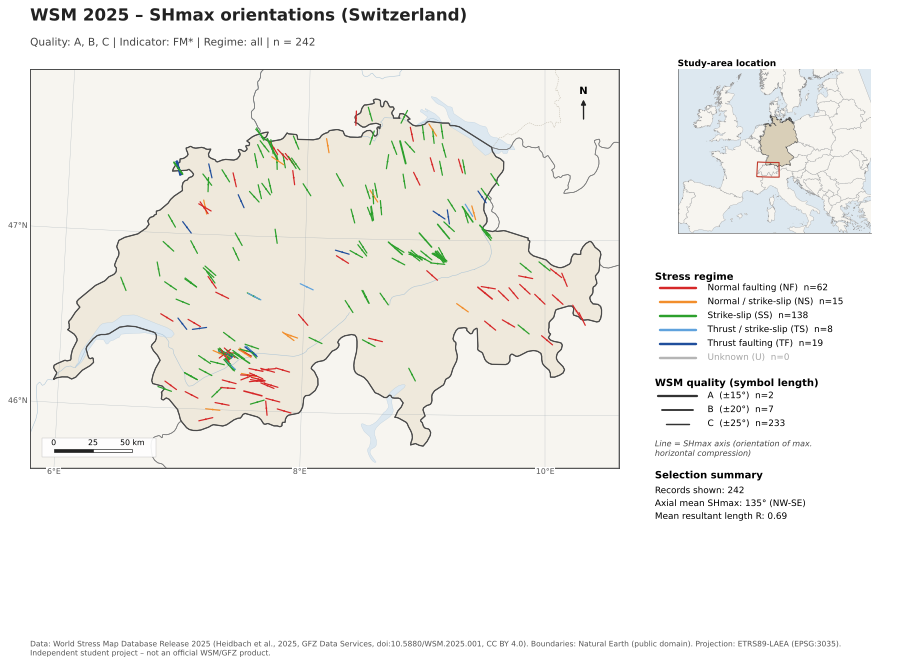

In [23]:
sel, steps, fig = filter_stress_data(gdf, region="Switzerland", quality="C",
                                     indicator="FM*", make_map=True)

CASMO-inspired filter -> region='Germany', quality=['A', 'B'], indicator='BO', regime=None, depth=None
      filter_step  n_records
            input     100672
           region        791
          quality        125
        indicator         88
           regime         88
            depth         88
has SHmax azimuth         88


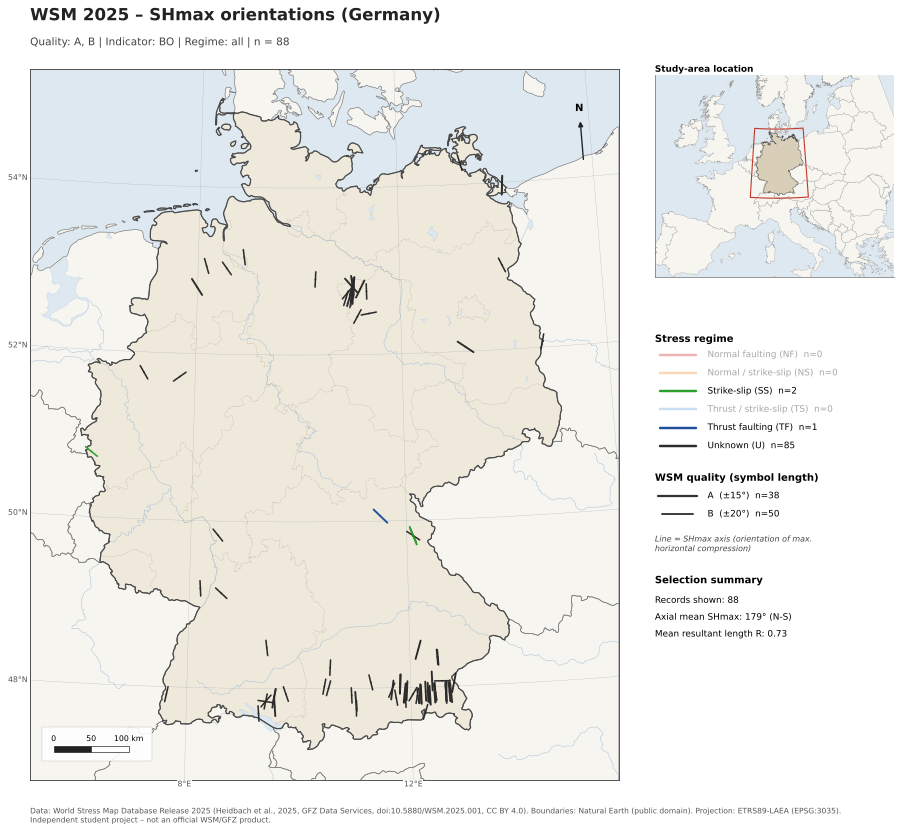

In [24]:
sel, steps, fig = filter_stress_data(gdf, region="Germany", quality=["A", "B"],
                                     indicator="BO", make_map=True)

CASMO-inspired filter -> region=(5.5, 45.6, 11.0, 48.2), quality='C', indicator=None, regime=['SS', 'NF'], depth=None
      filter_step  n_records
            input     100672
           region        828
          quality        473
        indicator        473
           regime        333
            depth        333
has SHmax azimuth        333


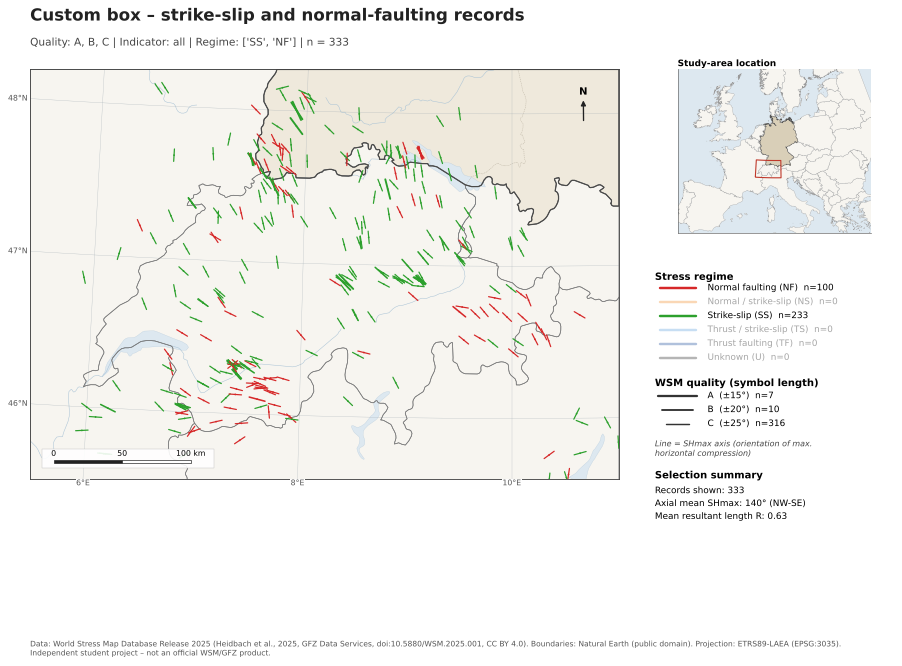

In [25]:
# a custom bounding box (lon_min, lat_min, lon_max, lat_max) and a regime filter
sel, steps, fig = filter_stress_data(gdf, region=(5.5, 45.6, 11.0, 48.2), quality="C",
                                     regime=["SS", "NF"], make_map=True,
                                     title="Custom box – strike-slip and normal-faulting records")

## 12. Export and check the exported files

In [26]:
paths = export_dataset(ce_all, "wsm_central_europe_clean")
back_csv = pd.read_csv(paths["csv"], low_memory=False)
back_gpkg = gpd.read_file(paths["gpkg"])
print(paths)
print("Same IDs in CSV / GPKG as in memory:",
      set(back_csv["ID"]) == set(back_gpkg["ID"]) == set(ce_all["ID"]), "| CRS:", back_gpkg.crs)

{'csv': PosixPath('/home/claude/github_repo/world-stress-map-central-europe/outputs/wsm_central_europe_clean.csv'), 'gpkg': PosixPath('/home/claude/github_repo/world-stress-map-central-europe/outputs/wsm_central_europe_clean.gpkg'), 'geojson': PosixPath('/home/claude/github_repo/world-stress-map-central-europe/outputs/wsm_central_europe_clean.geojson')}
Same IDs in CSV / GPKG as in memory: True | CRS: EPSG:4326


## 13. Summary

- Central Europe window: 2216 records, 1019 with quality A–C; Germany: 791 records, 297 A–C.
- A–C data are mostly single focal mechanisms (546) and borehole breakouts (343).
- Axial mean SHmax ≈ 155° (NW–SE to NNW–SSE), R ≈ 0.49. The arithmetic mean (≈116°) would be wrong.
- The orientation changes within the region (e.g. about N–S in the eastern Molasse Basin), so one mean value is only a rough summary.
- The NW–SE trend fits the known stress pattern of western/central Europe (e.g. Müller et al., 1992; Heidbach et al., 2018). Local interpretation is outside the scope of this project.

**Limitations:** uneven data coverage, different methods and depths, many unknown regimes, simple grid means (not the WSM smoothing method).